# MODELS

## cgan_conv.py

In [34]:
"""
models/cgan_conv.py
Convolutional Conditional GAN (cDCGAN).
Generator uses ConvTranspose2d. Discriminator uses Conv2d.
Conditioning is applied by concatenating a label-embedding as channels.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

class CondGenerator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=10, feature_maps=128):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes

        # project label to a spatial map and concatenate to noise channels
        self.label_emb = nn.Embedding(num_classes, num_classes)

        # We'll transform (z + label_embed) -> feature map and upsample to 28x28
        self.fc = nn.Linear(latent_dim + num_classes, feature_maps*7*7)

        self.net = nn.Sequential(
            # input: (feature_maps) x 7 x 7
            nn.ConvTranspose2d(feature_maps, feature_maps//2, kernel_size=4, stride=2, padding=1), # 14x14
            nn.BatchNorm2d(feature_maps//2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_maps//2, feature_maps//4, kernel_size=4, stride=2, padding=1), # 28x28
            nn.BatchNorm2d(feature_maps//4),
            nn.ReLU(True),

            nn.Conv2d(feature_maps//4, 1, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, z, labels):
        # labels: (B,)
        c = self.label_emb(labels)            # (B, num_classes)
        x = torch.cat([z, c], dim=1)          # (B, latent+num_classes)
        x = self.fc(x)                        # (B, feature_maps*7*7)
        x = x.view(x.size(0), -1, 7, 7)       # (B, feature_maps,7,7)
        img = self.net(x)
        return img


class CondDiscriminator(nn.Module):
    def __init__(self, num_classes=10, feature_maps=64):
        super().__init__()
        # project label to spatial map and concatenate as channels
        self.label_emb = nn.Embedding(num_classes, num_classes)

        # input channels = 1 (image) + num_classes (label map)
        in_ch = 1 + num_classes

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, feature_maps, kernel_size=4, stride=2, padding=1), #14x14
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(feature_maps, feature_maps*2, kernel_size=4, stride=2, padding=1), #7x7
            nn.BatchNorm2d(feature_maps*2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear((feature_maps*2)*7*7, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        # create label maps: expand embedding to spatial dimensions and concat
        batch = img.size(0)
        c = self.label_emb(labels)                         # (B, num_classes)
        c_map = c.unsqueeze(2).unsqueeze(3).expand(-1, -1, img.size(2), img.size(3))  # (B, num_classes, H, W)
        x = torch.cat([img, c_map], dim=1)
        return self.net(x)

## cgan_mlp.py

In [35]:
import torch.nn as nn
import torch

class CganMLPGenerator(nn.Module):
    """
    Gerador da cGAN usando MLP
    Recebe: vetor aleatório Z + embedding do rótulo
    Retorna: imagem 784 dimensões normalizada para [-1,1]
    """
    def __init__(self, z_dim=64, num_classes=10):
        super().__init__()

        # Embedding transforma rótulo em vetor numérico
        self.embed = nn.Embedding(num_classes, num_classes)

        # Rede MLP
        self.net = nn.Sequential(
            nn.Linear(z_dim + num_classes, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z, labels):
        l = self.embed(labels)
        x = torch.cat([z, l], 1)
        return self.net(x)


class CganMLPDiscriminator(nn.Module):
    """
    Discriminador da cGAN usando MLP
    Recebe: Imagem achatada + embedding do rótulo
    """
    def __init__(self, num_classes=10):
        super().__init__()
        self.embed = nn.Embedding(num_classes, num_classes)

        self.net = nn.Sequential(
            nn.Linear(784 + num_classes, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, x, labels):
        l = self.embed(labels)
        x = torch.cat([x, l], 1)
        return self.net(x)

## cnn.py

In [36]:
"""
models/cnn.py
CNN classifier for MNIST (convolutional).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # conv layers reduce spatial dims from 28->14->7
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(64 * 7 * 7, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)   # 14x14
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)   # 7x7
        x = self.dropout(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

## feature_extractor.py

In [37]:
"""
models/feature_extractor.py
Small CNN used as a feature extractor for FID/KID (trained or used as-is).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

class FeatureExtractorMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.fc = nn.Linear(64*7*7, 128)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

In [38]:
class FeatureExtractorMLP(nn.Module):
    def __init__(self, input_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            # nn.Linear(784, 512),
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128)
        )

    def forward(self, x):
        if x.dim() > 2:
            x = x.view(x.size(0), -1)
        return self.net(x)

## infogan_conv.py

In [39]:
"""
models/infogan_conv.py
Convolutional InfoGAN (simplified)
Generator conditioned on categorical code (one-hot) and continuous codes (optionally).
Discriminator outputs real/fake and Q-network predicts categorical code.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

class InfoGenConv(nn.Module):
    def __init__(self, latent_dim=62, cat_dim=10, cont_dim=2, feature_maps=128):
        super().__init__()
        self.latent_dim = latent_dim
        self.cat_dim = cat_dim
        self.cont_dim = cont_dim
        input_dim = latent_dim + cat_dim + cont_dim
        self.fc = nn.Linear(input_dim, feature_maps*7*7)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(feature_maps, feature_maps//2, 4, 2, 1), #14x14
            nn.BatchNorm2d(feature_maps//2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feature_maps//2, feature_maps//4, 4, 2, 1), #28x28
            nn.BatchNorm2d(feature_maps//4),
            nn.ReLU(True),

            nn.Conv2d(feature_maps//4, 1, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z, c_cat, c_cont):
        # c_cat: one-hot (B, cat_dim), c_cont: (B, cont_dim)
        x = torch.cat([z, c_cat, c_cont], dim=1)
        x = self.fc(x).view(x.size(0), -1, 7, 7)
        return self.net(x)


class InfoDiscQ(nn.Module):
    def __init__(self, cat_dim=10, cont_dim=2, feature_maps=64):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(1, feature_maps, 4, 2, 1), #14x14
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(feature_maps, feature_maps*2, 4, 2, 1), #7x7
            nn.BatchNorm2d(feature_maps*2),
            nn.LeakyReLU(0.1, inplace=True),
        )
        self.flatten = nn.Flatten()
        self.disc = nn.Sequential(
            nn.Linear((feature_maps*2)*7*7, 1),
            nn.Sigmoid()
        )
        # Q-network: predict categorical logits + continuous (regression)
        self.q_net = nn.Sequential(
            nn.Linear((feature_maps*2)*7*7, 128),
            nn.ReLU(True),
            nn.Linear(128, cat_dim + cont_dim)
        )

    def forward(self, x):
        f = self.feature_extractor(x)
        f_flat = self.flatten(f)
        validity = self.disc(f_flat)
        q_out = self.q_net(f_flat)
        # q_out: first cat_dim logits, then cont_dim continuous predictions
        return validity, q_out

## infogan_mlp.py

In [40]:
import torch.nn as nn
import torch

class InfoGANGenerator(nn.Module):
    """
    Gerador InfoGAN (MLP)
    Entrada: z (ruído) + c (código latente controlável)
    """
    def __init__(self, z_dim=64, c_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim + c_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z, c):
        return self.net(torch.cat([z, c], 1))


class InfoGANDiscriminatorQ(nn.Module):
    """
    Discriminador + Rede Q (estimativa do código c)
    """
    def __init__(self, c_dim=10):
        super().__init__()

        # Parte compartilhada
        self.shared = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2)
        )

        # Saída do discriminador
        self.disc = nn.Linear(256, 1)

        # Saída da rede Q (estimativa de c)
        self.q = nn.Linear(256, c_dim)

    def forward(self, x):
        f = self.shared(x)
        return self.disc(f), self.q(f)

# TRAIN

## train_cgan_mlp.py

In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_cgan_mlp(train_loader, epochs=1, z_dim=64):
    G = CganMLPGenerator(z_dim).cuda()
    D = CganMLPDiscriminator().cuda()

    optG = optim.Adam(G.parameters(), lr=2e-4)
    optD = optim.Adam(D.parameters(), lr=2e-4)

    loss_fn = nn.BCEWithLogitsLoss()

    for e in range(epochs):
        total_d, total_g = 0.0, 0.0
        for x, y in train_loader:
            x = x.view(len(x), -1).cuda()
            y = y.cuda()
            b = len(x)

            # Amostra ruído
            z = torch.randn(b, z_dim).cuda()

            # -------- Treina D ----------
            optD.zero_grad()

            real = D(x, y)
            fake = G(z, y)
            d_fake = D(fake.detach(), y)

            lossD = (
                loss_fn(real, torch.ones_like(real)) +
                loss_fn(d_fake, torch.zeros_like(d_fake))
            )

            lossD.backward()
            optD.step()

            # -------- Treina G ----------
            optG.zero_grad()
            g_fake = D(fake, y)
            lossG = loss_fn(g_fake, torch.ones_like(g_fake))

            lossG.backward()
            optG.step()

            total_d += lossD.item()
            total_g += lossG.item()

        print(f"[cGAN MLP] Epoch {e+1}/{epochs} D_loss={total_d/len(train_loader):.4f} G_loss={total_g/len(train_loader):.4f}")

    return G;

## train_cgan.py

In [42]:
"""
train/train_cgan.py
Training loop for convolutional conditional GAN.
"""
import torch
import torch.nn as nn
from torch import optim

def train_cgan(train_loader, device, latent_dim=100, epochs=10, lr=2e-4):
    G = CondGenerator(latent_dim=latent_dim).to(device)
    D = CondDiscriminator().to(device)
    optG = optim.Adam(G.parameters(), lr=lr, betas=(0.5,0.999))
    optD = optim.Adam(D.parameters(), lr=lr, betas=(0.5,0.999))
    loss_fn = nn.BCELoss()

    for ep in range(epochs):
        total_d, total_g = 0.0, 0.0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            b = x.size(0)
            real = torch.ones(b,1, device=device)
            fake = torch.zeros(b,1, device=device)

            # Train D
            z = torch.randn(b, latent_dim, device=device)
            fake_imgs = G(z, y)
            d_loss = loss_fn(D(x,y), real) + loss_fn(D(fake_imgs.detach(), y), fake)
            optD.zero_grad(); d_loss.backward(); optD.step()

            # Train G
            z = torch.randn(b, latent_dim, device=device)
            fake_imgs = G(z, y)
            g_loss = loss_fn(D(fake_imgs, y), real)
            optG.zero_grad(); g_loss.backward(); optG.step()

            total_d += d_loss.item(); total_g += g_loss.item()

        print(f"[cCGAN] Epoch {ep+1}/{epochs} D_loss={total_d/len(train_loader):.4f} G_loss={total_g/len(train_loader):.4f}")

    return G

## train_cnn.py

In [43]:
"""
train/train_cnn.py
Training loop for CNN classifier.
"""
import torch
import torch.nn as nn
from torch import optim

def train_cnn(train_loader, device, epochs=5, lr=1e-3):
    model = CNNClassifier().to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    model.train()
    for ep in range(epochs):
        total_loss = 0.0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            opt.step()
            total_loss += loss.item()
        print(f"[CNN] Epoch {ep+1}/{epochs} loss={total_loss/len(train_loader):.4f}")
    return model

## train_infogan_mlp.py

In [44]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

def train_infogan_mlp(train_loader, epochs=1, z_dim=64, c_dim=10):
    G = InfoGANGenerator(z_dim, c_dim).cuda()
    DQ = InfoGANDiscriminatorQ(c_dim).cuda()

    optG = optim.Adam(G.parameters(), lr=2e-4)
    optDQ = optim.Adam(DQ.parameters(), lr=2e-4)

    loss_fn = nn.BCEWithLogitsLoss()

    for e in range(epochs):
        total_d, total_adv, total_info = 0.0, 0.0, 0.0
        for x, _ in train_loader:
            x = x.view(len(x), -1).cuda()
            b = len(x)

            # Z + códigos C
            z = torch.randn(b, z_dim).cuda()
            c = F.one_hot(torch.randint(0, c_dim, (b,)), num_classes=c_dim).float().cuda()

            # ---------------- Treina D ----------------
            optDQ.zero_grad()
            real, _ = DQ(x)
            fake = G(z, c)
            d_fake, _ = DQ(fake.detach())

            lossD = (
                loss_fn(real, torch.ones_like(real)) +
                loss_fn(d_fake, torch.zeros_like(d_fake))
            )

            lossD.backward()
            optDQ.step()

            # ---------------- Treina G + Q ----------------
            optG.zero_grad()
            optDQ.zero_grad()

            d_fake, q = DQ(fake)

            adv_loss = loss_fn(d_fake, torch.ones_like(d_fake))
            info_loss = F.mse_loss(q, c)

            (adv_loss + info_loss).backward()
            optG.step()
            optDQ.step()

            total_d += lossD.item();
            total_adv += adv_loss.item();
            total_info += info_loss.item()

        print(f"[InfoGAN] Epoch {e+1}/{epochs} D_loss={total_d/len(train_loader):.4f} Adv_loss={total_adv/len(train_loader):.4f} Info_loss={total_info/len(train_loader):.4f}")

    return G

## train_infogan.py

In [45]:
"""
train/train_infogan.py
Training loop for convolutional InfoGAN.
"""
import torch
import torch.nn as nn
from torch import optim

def train_infogan(train_loader, device, latent_dim=62, cat_dim=10, cont_dim=2, epochs=10, lr=2e-4):
    G = InfoGenConv(latent_dim=latent_dim, cat_dim=cat_dim, cont_dim=cont_dim).to(device)
    DQ = InfoDiscQ(cat_dim=cat_dim, cont_dim=cont_dim).to(device)
    optG = optim.Adam(G.parameters(), lr=lr, betas=(0.5,0.999))
    optD = optim.Adam(DQ.parameters(), lr=lr, betas=(0.5,0.999))
    bce = nn.BCELoss()
    ce = nn.CrossEntropyLoss()
    mse = nn.MSELoss()

    for ep in range(epochs):
        total_d, total_g, total_q = 0.0, 0.0, 0.0
        for x,_ in train_loader:
            x = x.to(device)
            b = x.size(0)
            real = torch.ones(b,1, device=device)
            fake = torch.zeros(b,1, device=device)

            # Sample latents
            z = torch.randn(b, latent_dim, device=device)
            cat_idx = torch.randint(0, cat_dim, (b,), device=device)
            c_cat = torch.zeros(b, cat_dim, device=device).scatter_(1, cat_idx.unsqueeze(1), 1.0)
            c_cont = torch.randn(b, cont_dim, device=device) * 0.1

            # Train D (real and fake)
            fake_imgs = G(z, c_cat, c_cont)
            d_real, _ = DQ(x)
            d_fake, q_fake = DQ(fake_imgs.detach())
            d_loss = bce(d_real, real) + bce(d_fake, fake)

            optD.zero_grad()
            # Q-loss (predict categorical)
            q_loss = ce(q_fake[:, :cat_dim], cat_idx)
            (d_loss + q_loss).backward()
            optD.step()

            # Train G
            d_fake, q_fake = DQ(fake_imgs)
            g_loss = bce(d_fake, real)
            q_loss_g = ce(q_fake[:, :cat_dim], cat_idx) + mse(q_fake[:, cat_dim:], c_cont)
            optG.zero_grad()
            (g_loss + q_loss_g).backward()
            optG.step()

            total_d += d_loss.item(); total_g += g_loss.item(); total_q += q_loss.item()

        print(f"[InfoGAN] Epoch {ep+1}/{epochs} D_loss={total_d/len(train_loader):.4f} G_loss={total_g/len(train_loader):.4f} Q_loss={total_q/len(train_loader):.4f}")


    return G

# METRICS

## fid_kid.py

In [46]:
"""
metrics/fid_kid.py
Simplified FID/KID computation using a small feature extractor.
"""
import torch
import scipy.linalg
import numpy as np

def compute_fid(mu1, sigma1, mu2, sigma2):
    # Uses numpy sqrtm via torch.linalg if available
    diff = mu1 - mu2
    covmean = scipy.linalg.sqrtm((sigma1 @ sigma2).cpu().numpy()).real
    covmean = torch.tensor(covmean, dtype=torch.float32, device=sigma1.device)
    fid = diff.dot(diff) + torch.trace(sigma1 + sigma2 - 2*covmean)
    return float(fid)

def polynomial_kernel(x, y):
    return (x @ y.T / x.size(1) + 1) ** 3

def compute_kid(real_feats, fake_feats):
    K_rr = polynomial_kernel(real_feats, real_feats).mean()
    K_ff = polynomial_kernel(fake_feats, fake_feats).mean()
    K_rf = polynomial_kernel(real_feats, fake_feats).mean()
    return float(K_rr + K_ff - 2*K_rf)


## precision_recall.py

In [47]:
"""
metrics/precision_recall.py
Precision/Recall approximation using k-NN.
"""
import numpy as np
from sklearn.neighbors import NearestNeighbors

def precision_recall(real_feats, fake_feats, k=3):
    real = real_feats.cpu().numpy()
    fake = fake_feats.cpu().numpy()
    nn_r = NearestNeighbors(n_neighbors=k).fit(real)
    nn_f = NearestNeighbors(n_neighbors=k).fit(fake)
    dist_r, _ = nn_r.kneighbors(real)
    dist_f, _ = nn_f.kneighbors(fake)
    thr_r = dist_r[:, -1].mean()
    thr_f = dist_f[:, -1].mean()
    dist_f2r, _ = nn_r.kneighbors(fake)
    precision = (dist_f2r[:,0] < thr_r).mean()
    dist_r2f, _ = nn_f.kneighbors(real)
    recall = (dist_r2f[:,0] < thr_f).mean()
    return float(precision), float(recall)

## evaluate.py

In [48]:
"""
metrics/evaluate.py
Combine feature extraction and metric computations.
"""
import torch

def extract_features(loader, model, device, n_samples=2000):
    model.eval()
    feats = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            f = model(x)
            feats.append(f)
            if len(feats)*x.size(0) >= n_samples:
                break
    feats = torch.cat(feats)[:n_samples]
    return feats

# def evaluate_gan(generator, real_loader, device, latent_dim=100, conditional=False, n_samples=2000, feature_extractor_class=FeatureExtractorMNIST):
#     feat_model = feature_extractor_class().to(device)
def evaluate_gan(generator, real_loader, device, latent_dim=100, conditional=False, n_samples=2000, feature_extractor=None, cont_dim=2):
    # Handle feature_extractor instantiation if it's a class or None
    if feature_extractor is None:
        feat_model = FeatureExtractorMNIST().to(device)
    elif isinstance(feature_extractor, type):
        feat_model = feature_extractor().to(device)
    else:
        feat_model = feature_extractor.to(device)

    # feat_model = feature_extractor.to(device)
    real_feats = extract_features(real_loader, feat_model, device, n_samples=n_samples)

    # generate fakes
    generator.eval()
    with torch.no_grad():
        if conditional:
            # sample random labels
            labels = torch.randint(0,10,(n_samples,), device=device)
            z = torch.randn(n_samples, latent_dim, device=device)
            fake = generator(z, labels)
        else:
            # assume generator takes z, c_cat, c_cont in that order
            z = torch.randn(n_samples, latent_dim, device=device)
            c_cat = torch.zeros(n_samples,10, device=device).scatter_(1, torch.randint(0,10,(n_samples,), device=device).unsqueeze(1), 1.0)
            # c_cont = torch.randn(n_samples,2, device=device) * 0.1
            c_cont = torch.randn(n_samples, cont_dim, device=device) * 0.1
            try:
                fake = generator(z, c_cat, c_cont)
            except TypeError:
                # c = torch.cat([c_cat, c_cont], dim=1)
                # fake = generator(z, c)
                fake = generator(z, c_cat)

        fake_feats = feat_model(fake)

    mu_r = real_feats.mean(0); mu_f = fake_feats.mean(0)
    sigma_r = torch.cov(real_feats.T); sigma_f = torch.cov(fake_feats.T)

    fid = compute_fid(mu_r, sigma_r, mu_f, sigma_f)
    kid = compute_kid(real_feats, fake_feats)
    prec, rec = precision_recall(real_feats, fake_feats)

    return {"FID": fid, "KID": kid, "Precision": prec, "Recall": rec}

# UTILS

## plotting.py

In [49]:
"""
utils/plotting.py
Simple helpers to save image grids.
"""
import torch
from torchvision.utils import save_image
import os

def save_grid(tensor, filename, nrow=8):
    # expects tensor in [-1,1]
    os.makedirs(os.path.dirname(filename) or ".", exist_ok=True)
    save_image((tensor + 1) / 2.0, filename, nrow=nrow)

#


In [50]:
"""
data.py - data loaders (MNIST)
"""
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

def get_mnist_loaders(batch_size=128):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    train = datasets.MNIST("./mnist", train=True, download=True, transform=transform)
    test  = datasets.MNIST("./mnist", train=False, download=True, transform=transform)
    return DataLoader(train, batch_size=batch_size, shuffle=True), DataLoader(test, batch_size=batch_size)

In [51]:
import torch
import torch.nn.functional as F
import os # Import os for directory creation

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create 'outputs' directory if it doesn't exist
os.makedirs("outputs", exist_ok=True)

print("Device:", DEVICE)
train_loader, test_loader = get_mnist_loaders(batch_size=128)

# 1) Train CNN classifier
print("\n== Training CNN ==")
cnn = train_cnn(train_loader, DEVICE, epochs=3)
# evaluate CNN on test set (quick)
cnn.eval()
correct = total = 0
with torch.no_grad():
    for x,y in test_loader:
        x,y = x.to(DEVICE), y.to(DEVICE)
        preds = cnn(x).argmax(1)
        correct += (preds==y).sum().item()
        total += y.size(0)
print(f"CNN accuracy: {correct/total:.4f}")

# 2) Train convolutional cGAN
print("\n\n== Training convolutional cGAN ==")
G_cgan = train_cgan(train_loader, DEVICE, latent_dim=100, epochs=5)
torch.save(G_cgan.state_dict(), "outputs/cgan_conv.pth") # Save the convolutional cGAN

# 3) Train convolutional InfoGAN
print("\n\n== Training convolutional InfoGAN ==")
G_info = train_infogan(train_loader, DEVICE, latent_dim=62, cat_dim=10, cont_dim=2, epochs=5)
torch.save(G_info.state_dict(), "outputs/infogan_conv.pth") # Save the convolutional InfoGAN

# 4) Generate samples and evaluate
print("\n\n== Generating samples and evaluating ==")
# cGAN samples (conditional)
z = torch.randn(64, 100, device=DEVICE)
labels = torch.tensor([i%10 for i in range(64)], device=DEVICE)
fake_cgan = G_cgan(z, labels)
save_grid(fake_cgan.cpu(), "outputs/fake_cgan.png", nrow=8)

# InfoGAN samples
z = torch.randn(64, 62, device=DEVICE)
c_cat = torch.zeros(64,10, device=DEVICE).scatter_(1, torch.tensor([i%10 for i in range(64)], device=DEVICE).unsqueeze(1), 1.0)
c_cont = torch.zeros(64,2, device=DEVICE)
fake_info = G_info(z, c_cat, c_cont)
save_grid(fake_info.cpu(), "outputs/fake_info.png", nrow=8)

# Evaluate metrics
metrics_cgan = evaluate_gan(G_cgan, train_loader, DEVICE, latent_dim=100, conditional=True, n_samples=2000)
metrics_info = evaluate_gan(G_info, train_loader, DEVICE, latent_dim=62, conditional=False, n_samples=2000)

print("\ncGAN metrics:", metrics_cgan)
print("InfoGAN metrics:", metrics_info)
print("\nOutputs saved to outputs/")

Device: cuda

== Training CNN ==
[CNN] Epoch 1/3 loss=0.1707
[CNN] Epoch 2/3 loss=0.0603
[CNN] Epoch 3/3 loss=0.0490
CNN accuracy: 0.9887


== Training convolutional cGAN ==
[cCGAN] Epoch 1/5 D_loss=1.0013 G_loss=1.1701
[cCGAN] Epoch 2/5 D_loss=1.0906 G_loss=1.0293
[cCGAN] Epoch 3/5 D_loss=1.1256 G_loss=1.0317
[cCGAN] Epoch 4/5 D_loss=1.2301 G_loss=0.9113
[cCGAN] Epoch 5/5 D_loss=1.2720 G_loss=0.8713


== Training convolutional InfoGAN ==
[InfoGAN] Epoch 1/5 D_loss=0.4166 G_loss=2.2344 Q_loss=0.4876
[InfoGAN] Epoch 2/5 D_loss=0.3678 G_loss=2.5235 Q_loss=0.0832
[InfoGAN] Epoch 3/5 D_loss=0.6081 G_loss=1.9073 Q_loss=0.0967
[InfoGAN] Epoch 4/5 D_loss=0.6935 G_loss=1.6821 Q_loss=0.0866
[InfoGAN] Epoch 5/5 D_loss=0.7009 G_loss=1.6949 Q_loss=0.0793


== Generating samples and evaluating ==

cGAN metrics: {'FID': 0.02305695042014122, 'KID': 0.00019049644470214844, 'Precision': 0.3605, 'Recall': 0.464}
InfoGAN metrics: {'FID': 0.03685184568166733, 'KID': 3.504753112792969e-05, 'Precision': 0.2

In [52]:
import torch
import torch.nn.functional as F
import os # Import os for directory creation

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create 'outputs' directory if it doesn't exist
os.makedirs("outputs", exist_ok=True)

MLP_extrator = FeatureExtractorMLP().to(DEVICE) # Move feature extractor to device

print("Device:", DEVICE)
train_loader, test_loader = get_mnist_loaders(batch_size=128)

# 2) Train MLP cGAN
print("\n== Training MLP cGAN ==")
G_cgan = train_cgan_mlp(train_loader, epochs=5, z_dim=100)
torch.save(G_cgan.state_dict(), "outputs/cgan_mlp.pth") # Save the MLP cGAN

# 3) Train MLP InfoGAN
print("\n\n== Training MLP InfoGAN ==")
G_info = train_infogan_mlp(train_loader, epochs=5, z_dim=62, c_dim=10)
torch.save(G_info.state_dict(), "outputs/infogan_mlp.pth") # Save the MLP InfoGAN

# 4) Generate samples and evaluate
print("\n\n== Generating samples and evaluating ==")
# cGAN samples (conditional)
z = torch.randn(64, 100, device=DEVICE)
labels = torch.tensor([i%10 for i in range(64)], device=DEVICE)
fake_cgan = G_cgan(z, labels)
save_grid(fake_cgan.cpu(), "outputs/fake_cgan.png", nrow=8)

# InfoGAN samples
z = torch.randn(64, 62, device=DEVICE)
c_cat = torch.zeros(64,10, device=DEVICE).scatter_(1, torch.tensor([i%10 for i in range(64)], device=DEVICE).unsqueeze(1), 1.0)
c_cont = torch.zeros(64,2, device=DEVICE)
try:
    fake_info = G_info(z, c_cat, c_cont)
except TypeError:
    # InfoGAN MLP does not use c_cont, only z and c_cat
    fake_info = G_info(z, c_cat)
save_grid(fake_info.cpu(), "outputs/fake_info.png", nrow=8)

# Evaluate metrics
metrics_cgan = evaluate_gan(G_cgan, train_loader, DEVICE, latent_dim=100, conditional=True, n_samples=2000, feature_extractor=MLP_extrator)
metrics_info = evaluate_gan(G_info, train_loader, DEVICE, latent_dim=62, conditional=False, cont_dim=0, n_samples=2000, feature_extractor=MLP_extrator)

print("\nGAN metrics:", metrics_cgan)
print("InfoGAN metrics:", metrics_info)
print("\nOutputs saved to outputs/")

Device: cuda

== Training MLP cGAN ==
[cGAN MLP] Epoch 1/5 D_loss=0.2857 G_loss=4.6382
[cGAN MLP] Epoch 2/5 D_loss=0.1040 G_loss=5.7381
[cGAN MLP] Epoch 3/5 D_loss=0.2752 G_loss=5.7151
[cGAN MLP] Epoch 4/5 D_loss=0.3840 G_loss=4.3604
[cGAN MLP] Epoch 5/5 D_loss=0.2340 G_loss=4.6150


== Training MLP InfoGAN ==
[InfoGAN] Epoch 1/5 D_loss=0.7948 Adv_loss=0.6680 Info_loss=0.0905
[InfoGAN] Epoch 2/5 D_loss=0.7507 Adv_loss=0.6913 Info_loss=0.0901
[InfoGAN] Epoch 3/5 D_loss=0.8084 Adv_loss=0.6794 Info_loss=0.0902
[InfoGAN] Epoch 4/5 D_loss=0.8017 Adv_loss=0.6807 Info_loss=0.0902
[InfoGAN] Epoch 5/5 D_loss=0.9135 Adv_loss=0.6419 Info_loss=0.0902


== Generating samples and evaluating ==

GAN metrics: {'FID': 0.24072179198265076, 'KID': 0.0011641979217529297, 'Precision': 0.982, 'Recall': 0.0}
InfoGAN metrics: {'FID': 0.2689514756202698, 'KID': 0.0018911361694335938, 'Precision': 0.0, 'Recall': 0.0}

Outputs saved to outputs/


## generate_datasets.py

In [53]:
import os
import torch
import torch.nn.functional as F

os.makedirs("outputs", exist_ok=True)
N_SAMPLES = 60000
BATCH_SIZE = 100
print(f"Device: {DEVICE}")
print("Generating synthetic datasets...")

# Configuration for each model
models = [
    {
        "name": "cgan_mlp",
        "class": CganMLPGenerator,
        "args": {"z_dim": 100, "num_classes": 10},
        "path": "outputs/cgan_mlp.pth",
        "type": "cgan"
    },
    {
        "name": "cgan_conv",
        "class": CondGenerator,
        "args": {"latent_dim": 100, "num_classes": 10},
        "path": "outputs/cgan_conv.pth",
        "type": "cgan"
    },
    {
        "name": "infogan_mlp",
        "class": InfoGANGenerator,
        "args": {"z_dim": 62, "c_dim": 10},
        "path": "outputs/infogan_mlp.pth",
        "type": "infogan_mlp"
    },
    {
        "name": "infogan_conv",
        "class": InfoGenConv,
        "args": {"latent_dim": 62, "cat_dim": 10, "cont_dim": 2},
        "path": "outputs/infogan_conv.pth",
        "type": "infogan_conv"
    }
]

for m in models:
    print(f"\nProcessing {m['name']}...")

    # Instantiate model
    try:
        model = m["class"](**m["args"]).to(DEVICE)
    except Exception as e:
        print(f"Error instantiating {m['name']}: {e}")
        continue

    # Load weights
    if os.path.exists(m["path"]):
        try:
            model.load_state_dict(torch.load(m["path"], map_location=DEVICE))
            print(f"Loaded weights from {m['path']}")
        except Exception as e:
            print(f"Error loading weights for {m['name']}: {e}")
            continue
    else:
        print(f"Warning: {m['path']} not found. Skipping generation for this model.")
        continue

    model.eval()

    all_imgs = []
    all_labels = []

    with torch.no_grad():
        batches = N_SAMPLES // BATCH_SIZE
        for i in range(batches):
            # Generate balanced labels (0-9)
            labels = torch.randint(0, 10, (BATCH_SIZE,), device=DEVICE)

            if m["type"] == "cgan":
                # Correct param name depends on class
                dim = m["args"].get("z_dim", m["args"].get("latent_dim"))
                z = torch.randn(BATCH_SIZE, dim, device=DEVICE)
                imgs = model(z, labels)

            elif m["type"] == "infogan_mlp":
                dim = m["args"]["z_dim"]
                z = torch.randn(BATCH_SIZE, dim, device=DEVICE)
                c_onehot = F.one_hot(labels, num_classes=m["args"]["c_dim"]).float().cuda() # Ensure one-hot is on CUDA
                imgs = model(z, c_onehot)

            elif m["type"] == "infogan_conv":
                dim = m["args"]["latent_dim"]
                z = torch.randn(BATCH_SIZE, dim, device=DEVICE)
                cat_dim = m["args"]["cat_dim"]
                c_onehot = torch.zeros(BATCH_SIZE, cat_dim, device=DEVICE).scatter_(1, labels.unsqueeze(1), 1.0)
                c_cont = torch.randn(BATCH_SIZE, m["args"]["cont_dim"], device=DEVICE)
                imgs = model(z, c_onehot, c_cont)

            # Check output shape
            # MLP outputs (B, 784). Conv outputs (B, 1, 28, 28).
            # We should standardize to (B, 1, 28, 28) for consistency with CNN training.
            if imgs.dim() == 2: # MLP output
                imgs = imgs.view(BATCH_SIZE, 1, 28, 28)

            all_imgs.append(imgs.cpu())
            all_labels.append(labels.cpu())

    full_x = torch.cat(all_imgs)
    full_y = torch.cat(all_labels)

    save_path = f"outputs/synthetic_{m['name']}.pt"
    torch.save((full_x, full_y), save_path)
    print(f"Saved {full_x.shape[0]} samples to {save_path}")

Device: cuda
Generating synthetic datasets...

Processing cgan_mlp...
Loaded weights from outputs/cgan_mlp.pth
Saved 60000 samples to outputs/synthetic_cgan_mlp.pt

Processing cgan_conv...
Loaded weights from outputs/cgan_conv.pth
Saved 60000 samples to outputs/synthetic_cgan_conv.pt

Processing infogan_mlp...
Loaded weights from outputs/infogan_mlp.pth
Saved 60000 samples to outputs/synthetic_infogan_mlp.pt

Processing infogan_conv...
Loaded weights from outputs/infogan_conv.pth
Saved 60000 samples to outputs/synthetic_infogan_conv.pt


## experiment_augumentation.py

In [54]:
import torch
import torch.nn.functional as F
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset # Added TensorDataset and DataLoader imports

def evaluate_model(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

def get_real_tensors():
    """Manually load MNIST, normalize to [-1, 1] and return tensors."""
    print("Loading Real MNIST data...")
    # We do manual loading to easily concatenate tensors later
    ds = datasets.MNIST("./mnist", train=True, download=True)

    # ds.data is (N, 28, 28) uint8 in [0, 255]
    x = ds.data.float() / 255.0
    # Normalize to [-1, 1] -> (val - 0.5) / 0.5
    x = (x - 0.5) / 0.5

    # Add channel dim: (N, 28, 28) -> (N, 1, 28, 28)
    x = x.unsqueeze(1)

    y = ds.targets
    return x, y

def run_experiment():
    print(f"Running Data Augmentation Experiment on {DEVICE}...")

    # 1. Baseline: Train on Real Data Only
    print("\n--- 1. Baseline (Real MNIST Only) ---")
    train_loader_real, test_loader = get_mnist_loaders(batch_size=128)

    # We retrain the baseline CNN here to ensure fair comparison (fresh weights)
    cnn_baseline = train_cnn(train_loader_real, DEVICE, epochs=5) # increased epochs slightly for stability
    acc_baseline = evaluate_model(cnn_baseline, test_loader, DEVICE)
    print(f"Baseline Accuracy: {acc_baseline:.4f}")

    results = [
        {"Dataset": "MNIST (Baseline)", "Accuracy": acc_baseline}
    ]

    # 2. Augmentation with Synthetic Data
    synthetic_files = [
        "cgan_mlp",
        "cgan_conv",
        "infogan_mlp",
        "infogan_conv"
    ]

    # Helper to clean memory
    del cnn_baseline
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

    # Load Real Tensors for concatenation
    real_x, real_y = get_real_tensors()

    for name in synthetic_files:
        path = f"outputs/synthetic_{name}.pt"
        if not os.path.exists(path):
            print(f"\nWarning: {path} not found. Skipping.")
            continue

        print(f"\n--- Augmenting with {name} ---")

        # Load synthetic
        fake_x, fake_y = torch.load(path)
        print(f"Loaded {fake_x.size(0)} synthetic samples.")

        # Combine
        combined_x = torch.cat([real_x, fake_x])
        combined_y = torch.cat([real_y, fake_y])

        print(f"Total training samples: {combined_x.size(0)}")

        # Create DataLoader
        dataset_augmented = TensorDataset(combined_x, combined_y)
        loader_augmented = DataLoader(dataset_augmented, batch_size=128, shuffle=True)

        # Train CNN
        print("Retraining CNN...")
        cnn_aug = train_cnn(loader_augmented, DEVICE, epochs=5)

        # Evaluate
        acc = evaluate_model(cnn_aug, test_loader, DEVICE)
        print(f"Accuracy with {name}: {acc:.4f}")

        results.append({
            "Dataset": f"MNIST + {name}",
            "Accuracy": acc
        })

        # Cleanup
        del cnn_aug, dataset_augmented, loader_augmented, combined_x, combined_y, fake_x, fake_y
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    # 3. Final Report
    print("\n\n=== Experiment Results ===")
    print(f"{'Dataset':<25} | {'Accuracy':<10}")
    print("-" * 40)
    for r in results:
        print(f"{r['Dataset']:<25} | {r['Accuracy']:.4f}")

run_experiment() # Call the experiment function

Running Data Augmentation Experiment on cuda...

--- 1. Baseline (Real MNIST Only) ---
[CNN] Epoch 1/5 loss=0.1737
[CNN] Epoch 2/5 loss=0.0617
[CNN] Epoch 3/5 loss=0.0501
[CNN] Epoch 4/5 loss=0.0433
[CNN] Epoch 5/5 loss=0.0380
Baseline Accuracy: 0.9887
Loading Real MNIST data...

--- Augmenting with cgan_mlp ---
Loaded 60000 synthetic samples.
Total training samples: 120000
Retraining CNN...
[CNN] Epoch 1/5 loss=1.1297
[CNN] Epoch 2/5 loss=0.9867
[CNN] Epoch 3/5 loss=0.9222
[CNN] Epoch 4/5 loss=0.8716
[CNN] Epoch 5/5 loss=0.8346
Accuracy with cgan_mlp: 0.9829

--- Augmenting with cgan_conv ---
Loaded 60000 synthetic samples.
Total training samples: 120000
Retraining CNN...
[CNN] Epoch 1/5 loss=0.0981
[CNN] Epoch 2/5 loss=0.0466
[CNN] Epoch 3/5 loss=0.0372
[CNN] Epoch 4/5 loss=0.0324
[CNN] Epoch 5/5 loss=0.0270
Accuracy with cgan_conv: 0.9875

--- Augmenting with infogan_mlp ---
Loaded 60000 synthetic samples.
Total training samples: 120000
Retraining CNN...
[CNN] Epoch 1/5 loss=1.2366


# Análise Gráfica dos Modelos

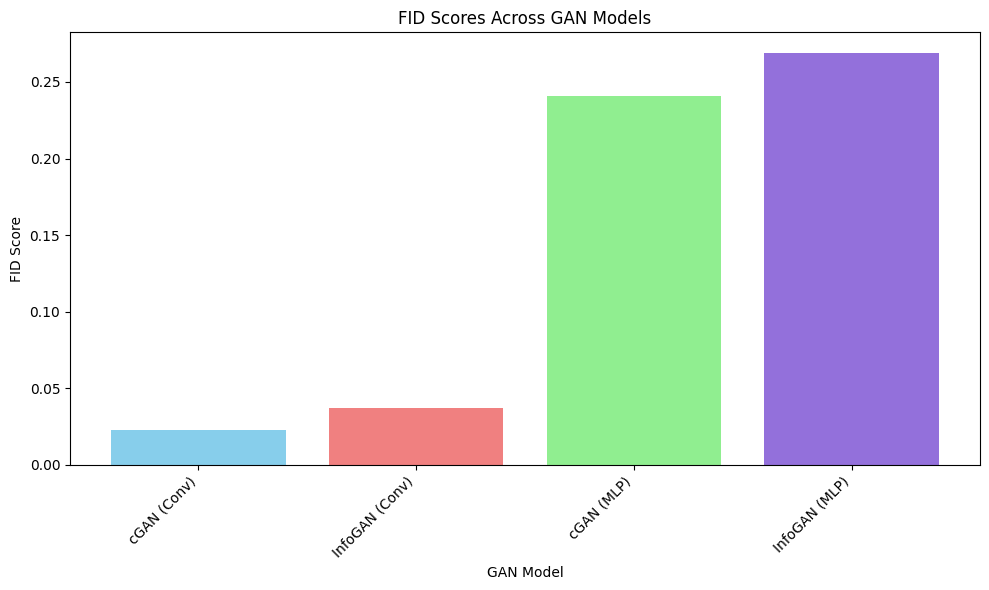

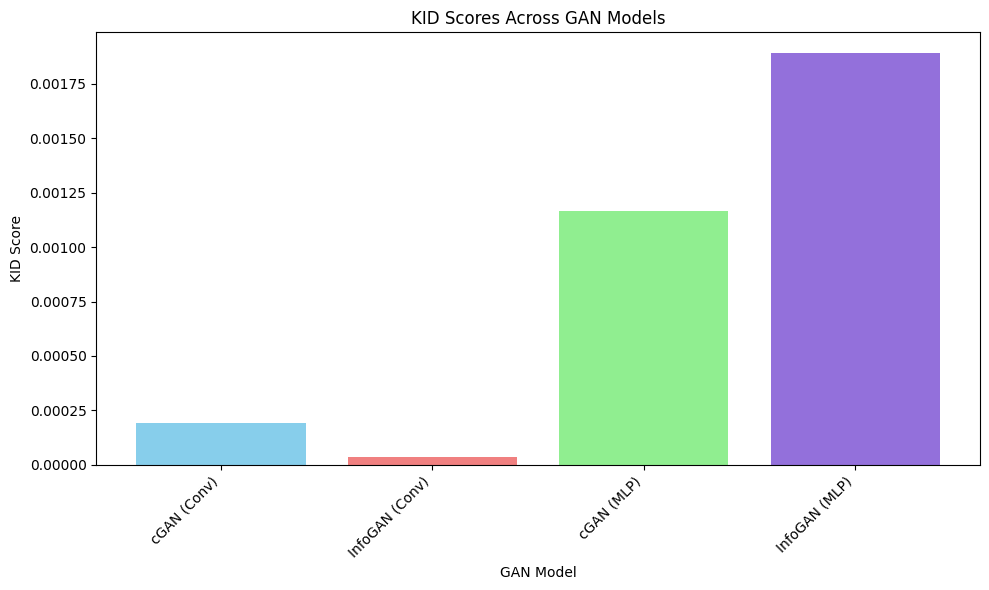

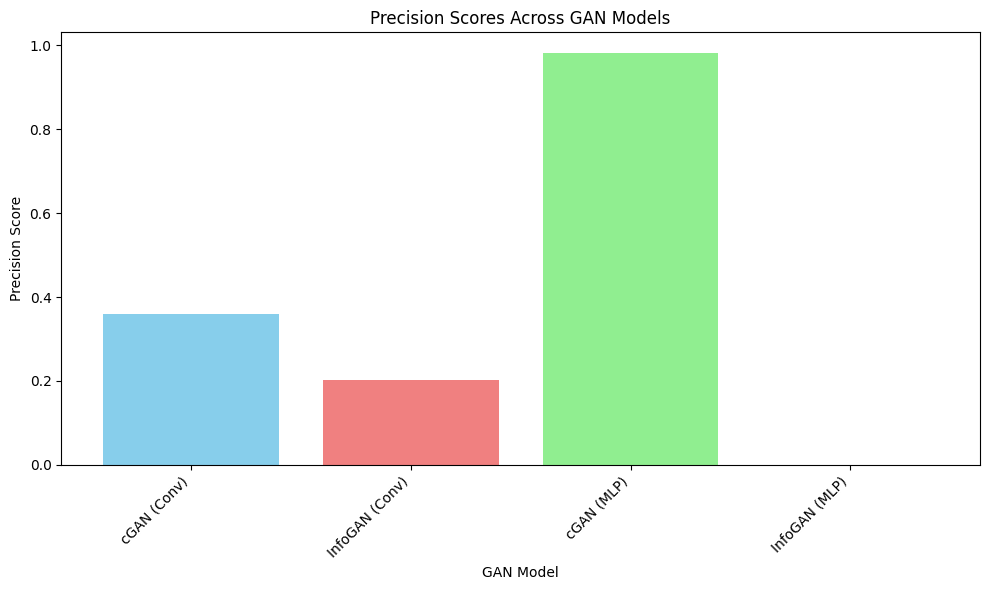

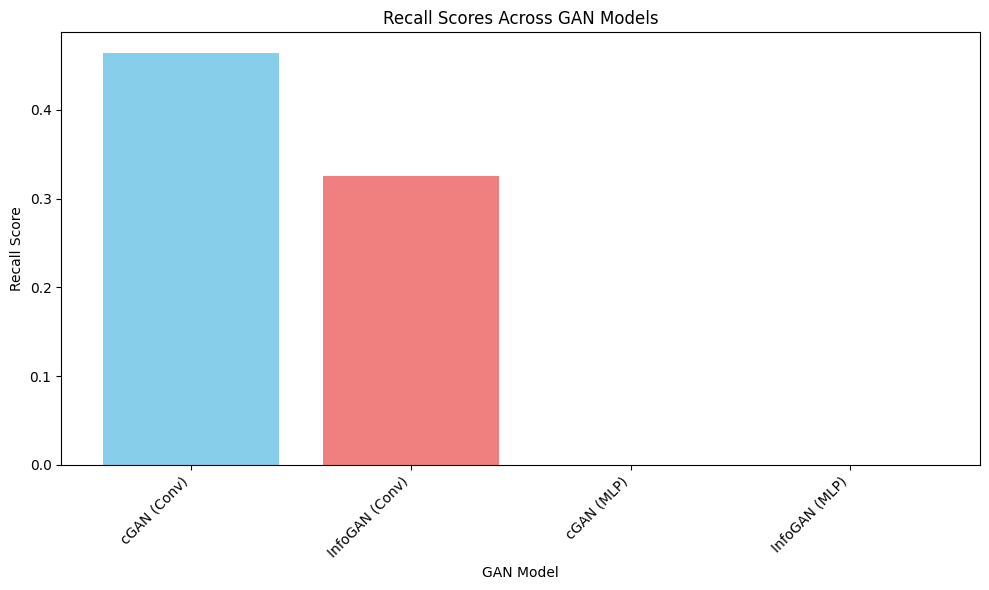

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

conv_gan_metrics_cgan = {'FID': 0.02305695042014122, 'KID': 0.00019049644470214844, 'Precision': 0.3605, 'Recall': 0.464}
conv_gan_metrics_info = {'FID': 0.03685184568166733, 'KID': 3.504753112792969e-05, 'Precision': 0.203, 'Recall': 0.3255}
mlp_gan_metrics_cgan = {'FID': 0.24072179198265076, 'KID': 0.0011641979217529297, 'Precision': 0.982, 'Recall': 0.0}
mlp_gan_metrics_info = {'FID': 0.2689514756202698, 'KID': 0.0018911361694335938, 'Precision': 0.0, 'Recall': 0.0}

gan_metrics_list = [
    {'Model': 'cGAN (Conv)', **conv_gan_metrics_cgan},
    {'Model': 'InfoGAN (Conv)', **conv_gan_metrics_info},
    {'Model': 'cGAN (MLP)', **mlp_gan_metrics_cgan},
    {'Model': 'InfoGAN (MLP)', **mlp_gan_metrics_info}
]
gan_metrics_df = pd.DataFrame(gan_metrics_list)

metrics_to_plot = ['FID', 'KID', 'Precision', 'Recall']

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 6))
    bars = plt.bar(gan_metrics_df['Model'], gan_metrics_df[metric], color=['skyblue', 'lightcoral', 'lightgreen', 'mediumpurple'])
    plt.title(f'{metric} Scores Across GAN Models')
    plt.xlabel('GAN Model')
    plt.ylabel(f'{metric} Score')
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

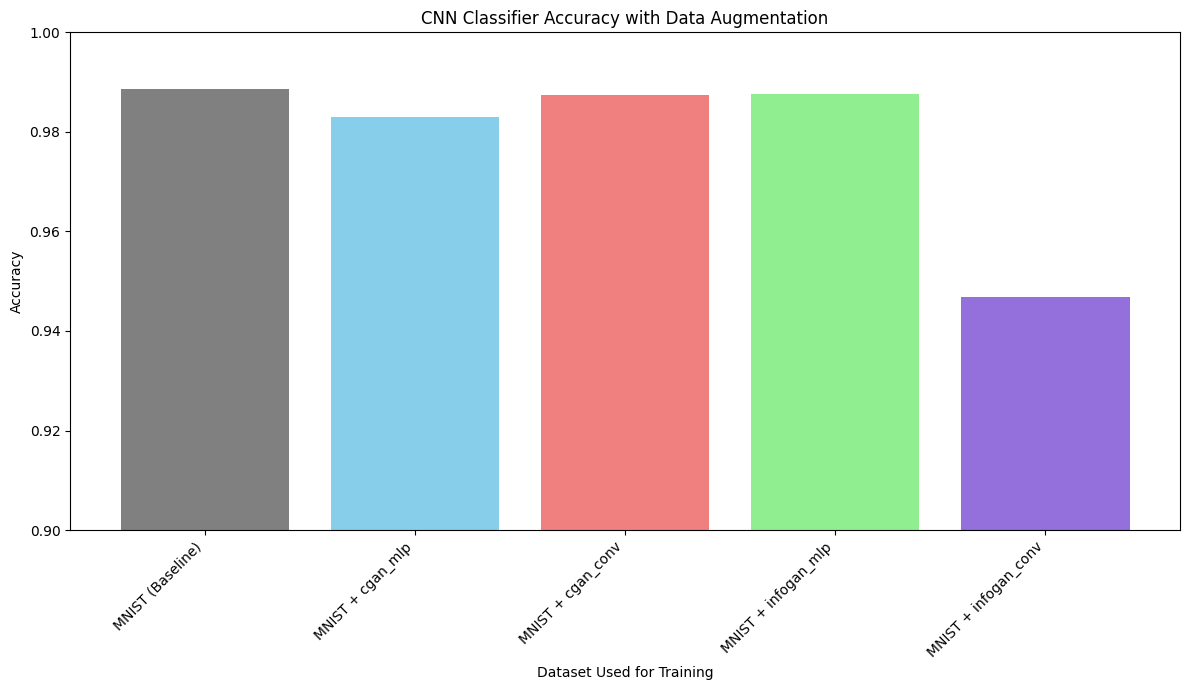

CNN classifier accuracy bar chart generated.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

cnn_accuracies_raw = [
    {"Dataset": "MNIST (Baseline)", "Accuracy": 0.9887},
    {"Dataset": "MNIST + cgan_mlp", "Accuracy": 0.9829},
    {"Dataset": "MNIST + cgan_conv", "Accuracy": 0.9875},
    {"Dataset": "MNIST + infogan_mlp", "Accuracy": 0.9876},
    {"Dataset": "MNIST + infogan_conv", "Accuracy": 0.9468}
]
cnn_accuracy_df = pd.DataFrame(cnn_accuracies_raw)

plt.figure(figsize=(12, 7))
plt.bar(cnn_accuracy_df['Dataset'], cnn_accuracy_df['Accuracy'], color=['gray', 'skyblue', 'lightcoral', 'lightgreen', 'mediumpurple'])
plt.title('CNN Classifier Accuracy with Data Augmentation')
plt.xlabel('Dataset Used for Training')
plt.ylabel('Accuracy')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("CNN classifier accuracy bar chart generated.")